# Length vs. Growth rate slope analysis
## Parse lLAG8 data

In [497]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score

In [498]:
def get_grna_data(df_,
                  cols_grnas = ['opLAG1_id', 'sgRNA', 'locus_tag', 'Gene', 'Predicted_Efficacy', 'Category',
       'TargetID', 'N Observations', 'N Observations Proliferating']):
    df_bar = (
        df_
        .reset_index()
        .loc[:, cols_grnas]
        .drop_duplicates('opLAG1_id')
        .sort_values(by='opLAG1_id')
        )
    return df_bar

def pivot_and_clean_steady_state_df(df_):
    df_ = (df_
     .reset_index()
     .pivot(index='opLAG1_id',
            columns=['Estimator', 'Variable(s)'],
            values = 'Value')
        .reset_index()
        # .pipe(lambda df: df.rename(columns=lambda x: '_'.join(x) if isinstance(x, tuple) else x))
        [['opLAG1_id','Mean (Robust)']]
        # .reset_index()
        # Remove multi-index columns
    )
    df_.columns = df_.columns.map(lambda x: x[1] if x[0] == 'Mean (Robust)' else x[0])
    return df_

In [499]:
headpath = '/home/gutil/scratch/2025-06-23_Slopes-Gene-Groups-Sandbox/'
df_cycle = pd.read_pickle(headpath + '2025-06-03_lLAG8_Steady_State_Cell_Cycle_df_Estimators.pkl')
df_obs = pd.read_pickle(headpath + '2025-06-03_lLAG8_Steady_State_Timepoints_df_Estimators.pkl')
df_gro = pd.read_pickle(headpath + '2025-06-03_lLAG8_Steady_State_Growth_df_Estimators.pkl')

df_obs = pivot_and_clean_steady_state_df(df_obs)
df_gro = pivot_and_clean_steady_state_df(df_gro)
df_bar = get_grna_data(df_cycle)
df_cycle = pivot_and_clean_steady_state_df(df_cycle)

phenotypes = (
    df_obs
     .merge(df_gro, on='opLAG1_id', how='inner')
     .merge(df_cycle, on='opLAG1_id', how='inner')
     .merge(df_bar, on='opLAG1_id', how='inner')
)

phenotypes_controls = phenotypes[phenotypes['Category'] == 'control']
phenotypes = phenotypes[phenotypes['Category'] != 'control']

In [510]:
genes_with_low_growth_rates = phenotypes[phenotypes['Instantaneous Growth Rate: Volume'] < 0.8].groupby('Gene').size()

In [ ]:
N_POINTS_LOW_GROWTH_RATE_CUTOFF = 3
genes_to_keep_low_growth_rate = genes_with_low_growth_rates[genes_with_low_growth_rates >= N_POINTS_LOW_GROWTH_RATE_CUTOFF]
phenotypes_low_growth_rates = phenotypes[phenotypes['Gene'].isin(genes_to_keep_low_growth_rate.index)]

<Axes: title={'center': 'Control Growth Rate vs Length'}, xlabel='Instantaneous Growth Rate: Volume', ylabel='Length'>

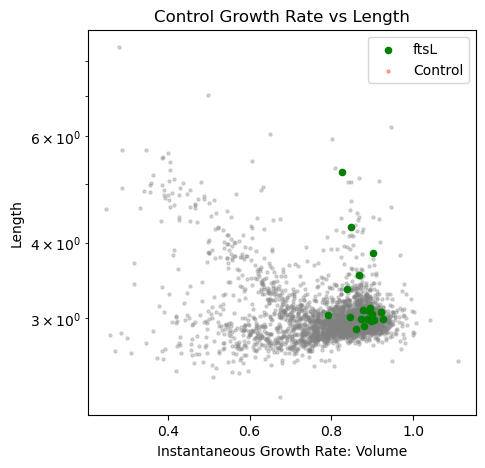

In [526]:
# df.to_pickle(headpath + '2025-06-23_lLAG8_Steady_State_Pivoted_Robust_Estimators.pkl')
x_var = 'Instantaneous Growth Rate: Volume'
y_var = 'Length'
fig, ax = plt.subplots(figsize=(5, 5))
# Make y axis log
ax.set_yscale('log')
# ax.set_xscale('log')
phenotypes.plot(x=x_var, y=y_var, kind='scatter', title='Growth Rate vs Length', ax=ax, color='gray', s=5, alpha=0.3)
# phenotypes_low_growth_rates.plot(x=x_var, y=y_var, kind='scatter', title='Low Growth Rate vs Length', ax=ax, color='blue', s=5, alpha=0.3)
# df[df['Gene'] == 'rplM'].plot(x = x_var, y = y_var, kind='scatter', title='dnaA Growth Rate vs Length', ax=ax, color='red', label='dnaA')
phenotypes[phenotypes['Gene'] == 'ftsL'].plot(x=x_var, y=y_var, kind='scatter', title='ftsL Growth Rate vs Length', ax=ax, color='green', label='ftsL')
phenotypes[phenotypes['Category'] == 'control'].plot(x=x_var, y=y_var, kind='scatter', title='Control Growth Rate vs Length', ax=ax, color='red', s=5, label='Control', alpha = 0.3)

## Perform linear fit

In [527]:
def length_vs_growth_predictions_genes(df_):
    # df_ already for a single gene
    regression = linear_model.LinearRegression()
    x_col_label = 'Instantaneous Growth Rate: Volume'
    y_col_label = 'Length'
    X = df_[[x_col_label]].values
    y = np.log2(df_[[y_col_label]].values) 
    regression.fit(X, y)
    y_pred = regression.predict(X)
    mse = mean_squared_error(y, y_pred)
    r2 = r2_score(y, y_pred)

    return pd.DataFrame({'Gene': df_.name, 
                         'Slope': regression.coef_[0][0],
                         'Intercept': regression.intercept_[0],
                         'MSE': mse,
                         'R2': r2}, index=[0])

In [528]:
slopes = phenotypes_low_growth_rates.groupby('Gene').apply(length_vs_growth_predictions_genes, include_groups=False).reset_index(drop=True)

## Parse subtiwiki gene dataset

In [530]:
headpath

'/home/gutil/scratch/2025-06-23_Slopes-Gene-Groups-Sandbox/'

In [531]:
gene_categories_per_gene = (pd
                            .read_csv(headpath + '2025-06-24_subti_wiki_export_genes.tsv',
                                      sep='\t',
                                      usecols=['id', 'legacy_id', 'name', 'synonyms', 'categories', 'essential'])
                            .dropna(subset=['categories']))
gene_categories_id_lookup = (pd
                             .read_csv(headpath + '2025-06-24_12-33-00_subti_wiki_export_categories.csv',
                                       usecols = ['id', 'dot_notation', 'name']))

In [532]:
def filter_by_gene_category(phenotypes_, gene_category_id_startswith):
    ids = gene_categories_id_lookup.loc[gene_categories_id_lookup['dot_notation']
                                    .str.startswith(gene_category_id_startswith)
                                    ,'id']

    ids_for_lookup = ['('+str(id)+')' for id in ids]
    id_lookup_pattern = '|'.join(re.escape(id) for id in ids_for_lookup)

    gene_category_subset = gene_categories_per_gene.loc[gene_categories_per_gene['categories']
                                                        .str.contains(id_lookup_pattern, na=False, regex=True)
                                                        ,:]

    query_for_phenotypes = (
        (phenotypes_['Gene']
        .isin(gene_category_subset['name']))
        | 
        (phenotypes_['Gene']
        .isin(gene_category_subset['synonyms'].dropna()))
    )

    phenotypes_category = phenotypes_.loc[(phenotypes_['Gene']
                                        .isin(gene_category_subset['name']))
                                        | 
                                        (phenotypes_['Gene']
                                        .isin(gene_category_subset['synonyms'].dropna()))]

    gene_names_in_phenotype_df = phenotypes_category['Gene'].unique()
    slopes_category = slopes.loc[slopes['Gene'].isin(gene_names_in_phenotype_df)]

    return phenotypes_category, slopes_category

### Do it for a handful

In [533]:
phenotypes_carbon, slopes_carbon = filter_by_gene_category(phenotypes_low_growth_rates, '2.2')
phenotypes_lipid, slopes_lipid = filter_by_gene_category(phenotypes_low_growth_rates, '2.4')

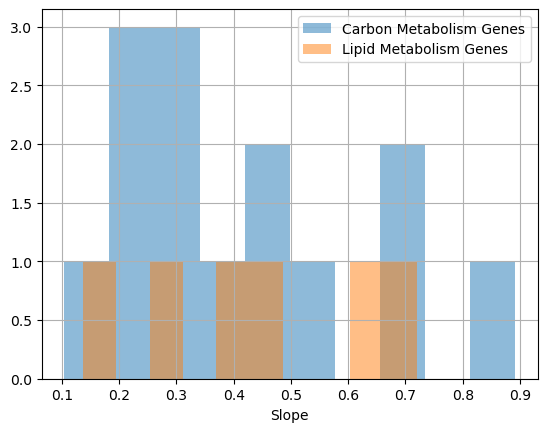

In [534]:
density = False
# slopes['Slope'].hist(bins = 30, density=density, alpha=0.5, label='All Genes')
# df_ribo['Slope'].hist(bins = 30, density=density, alpha=0.5, label='Ribosomal Genes')
slopes_carbon['Slope'].hist(bins = 10, density=density, alpha=0.5, label='Carbon Metabolism Genes')
slopes_lipid['Slope'].hist(bins = 10, density=density, alpha=0.5, label='Lipid Metabolism Genes')
# df_trna['Slope'].hist(bins = 10, density=density, alpha=0.5, label='tRNA Synthetases')
# df_fatty_acid['Slope'].hist(bins = 10, density=density, alpha=0.5, label='Fatty Acid Synthesis Genes')
# df_fts['Slope'].hist(bins = 10, density=density, alpha=0.5, label='Fts Genes')
plt.xlabel('Slope')
# plt.ylim([0,2])
plt.legend()


<Axes: title={'center': 'Carbon Metabolism  Rate vs Length'}, xlabel='Instantaneous Growth Rate: Volume', ylabel='Length'>

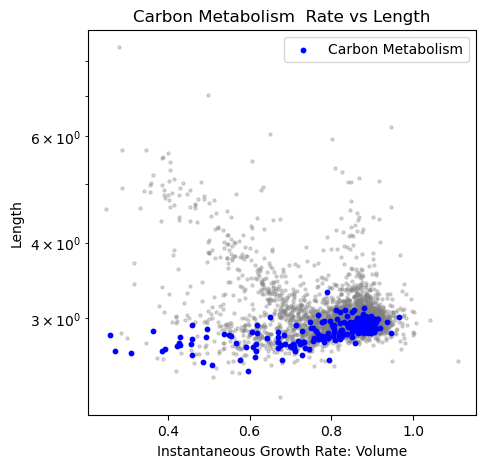

In [536]:
# df.to_pickle(headpath + '2025-06-23_lLAG8_Steady_State_Pivoted_Robust_Estimators.pkl')
x_label = 'Instantaneous Growth Rate: Volume'
y_label = 'Length'
fig, ax = plt.subplots(figsize=(5, 5))
# Make y axis log
ax.set_yscale('log')
# ax.set_xscale('log')
phenotypes.plot(x=x_label, y=y_label, kind='scatter', title='Growth Rate vs Length', ax=ax, color='gray', s=5, alpha=0.3)
# df[df['Gene'] == 'rplM'].plot(x = x_var, y = y_var, kind='scatter', title='dnaA Growth Rate vs Length', ax=ax, color='red', label='dnaA')
phenotypes_carbon.plot(x=x_var, y=y_var, kind='scatter', title='Carbon Metabolism  Rate vs Length', ax=ax, color='blue', label='Carbon Metabolism', s=10)
# phenotypes_lipid.plot(x=x_label, y=y_label, kind='scatter', title='Lipid Metabolism Growth Rate vs Length', ax=ax, color='orange', label='Lipid Metabolism', s=10, alpha=1)
# phenotypes[phenotypes['Category'] == 'control'].plot(x=x_var, y=y_var, kind='scatter', title='Control Growth Rate vs Length', ax=ax, color='red', s=5, label='Control', alpha = 0.3)

### Do it systematically

In [537]:
headpath + '2025-06-24_12-33-00_subti_wiki_selected_categories.csv'

'/home/gutil/scratch/2025-06-23_Slopes-Gene-Groups-Sandbox/2025-06-24_12-33-00_subti_wiki_selected_categories.csv'

In [538]:
gene_categories_to_analyze = pd.read_csv(headpath + '2025-06-24_12-33-00_subti_wiki_selected_categories.csv', usecols=['dot_notation', 'name'])

In [539]:
category_filter_and_slopes = {gene_category_id_startswith:
                              filter_by_gene_category(phenotypes_low_growth_rates,
                                                      gene_category_id_startswith)
                              for gene_category_id_startswith in gene_categories_to_analyze['dot_notation']}

Analyzing category: Aminoacyl-tRNA synthetases
['argS' 'aspS' 'gatA' 'gatB' 'hisZ' 'ileS' 'metS' 'proS' 'trpS' 'tyrS']


<Axes: >

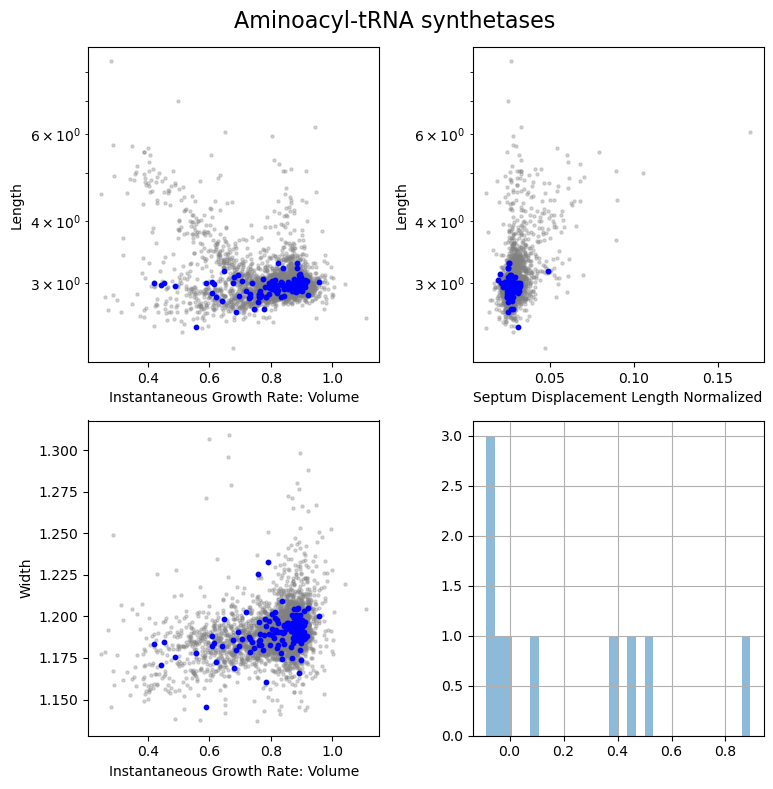

In [548]:
gene_category_id_startswith = '3.3.1.10' # Compare 2.2.1 with 2.2.1.1
gene_category_title = gene_categories_to_analyze[gene_categories_to_analyze['dot_notation'] == gene_category_id_startswith]['name'].iloc[0]
print(f'Analyzing category: {gene_category_title}')
gene_categories_to_analyze[gene_categories_to_analyze['dot_notation'].str.startswith('1.1.1')]

phenotypes_category = category_filter_and_slopes[gene_category_id_startswith][0]
slopes_category = category_filter_and_slopes[gene_category_id_startswith][1]
print(slopes_category['Gene'].unique())
x_labels = [['Instantaneous Growth Rate: Volume', 'Septum Displacement Length Normalized'],
            ['Instantaneous Growth Rate: Volume', '']]
y_labels =  [['Length', 'Length'],
            ['Width', '']]
fig, axs = plt.subplots(2, 2, figsize=(8, 8), tight_layout=True)
# plt.title(f'Growth Rate vs Length and Width for {gene_category_title} Genes')
axs[0,0].set_yscale('log')
axs[0,1].set_yscale('log')
fig.suptitle(gene_category_title, fontsize=16)
phenotypes.plot(x=x_labels[0][0], y=y_labels[0][0], kind='scatter', ax=axs[0, 0], color='gray', s=5, alpha=0.3)
phenotypes_category.plot(x=x_labels[0][0], y=y_labels[0][0], kind='scatter', ax=axs[0, 0], color='blue', s=10, alpha=1)
phenotypes.plot(x=x_labels[0][1], y=y_labels[0][1], kind='scatter', ax=axs[0, 1], color='gray', s=5, alpha=0.3)
phenotypes_category.plot(x=x_labels[0][1], y=y_labels[0][1], kind='scatter', ax=axs[0, 1], color='blue', s=10, alpha=1)
phenotypes.plot(x=x_labels[1][0], y=y_labels[1][0], kind='scatter', ax=axs[1, 0], color='gray', s=5, alpha=0.3)
phenotypes_category.plot(x=x_labels[1][0], y=y_labels[1][0], kind='scatter', ax=axs[1, 0], color='blue', s=10, alpha=1)


# slopes['Slope'].hist(bins=30, density=False, alpha=0.5, label='All Genes', fill=False)
slopes_category['Slope'].hist(bins=30, density=False, alpha=0.5, label=f'{gene_category_title} Genes')


Text(0.5, 0, 'Slope')

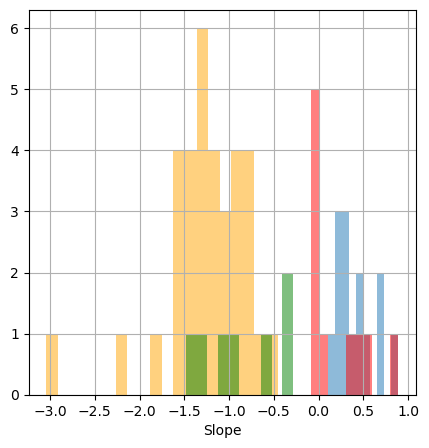

In [563]:
fig, ax = plt.subplots(figsize=(5, 5))

gene_category_id_startswith = '2.2'  # Carbon Metabolism
phenotypes_category = category_filter_and_slopes[gene_category_id_startswith][0]
slopes_category = category_filter_and_slopes[gene_category_id_startswith][1]
slopes_category['Slope'].hist(density=False, alpha=0.5, label=f'{gene_category_title} Genes', ax=ax)

gene_category_id_startswith = '3.3.1.4'  # Ribosomal proteins
phenotypes_category = category_filter_and_slopes[gene_category_id_startswith][0]
slopes_category = category_filter_and_slopes[gene_category_id_startswith][1]
slopes_category['Slope'].hist(density=False, bins=20, alpha=0.5, label=f'{gene_category_title} Genes', ax=ax, color='orange')

gene_category_id_startswith = '3.3.1.10' # tRNA synth
phenotypes_category = category_filter_and_slopes[gene_category_id_startswith][0]
slopes_category = category_filter_and_slopes[gene_category_id_startswith][1]
slopes_category['Slope'].hist(density=False, alpha=0.5, label=f'{gene_category_title} Genes', ax=ax, color='red')

gene_category_id_startswith = '3.3.1.11'  # Translation Factors
phenotypes_category = category_filter_and_slopes[gene_category_id_startswith][0]
slopes_category = category_filter_and_slopes[gene_category_id_startswith][1]
slopes_category['Slope'].hist(density=False, alpha=0.5, label=f'{gene_category_title} Genes', ax=ax, color='green')
# gene_category_id_startswith = '2.2'  # Lipid Metabolism

plt.xlabel('Slope')


# TODO
- Include the nonessentials, at least in the visualization, see if they help
- Include E. coli data?

- Check individual genes for trends, find good examples
- 